# Тема 2. Моделирование связи частотного и классического определения вероятности
> Приведите пример, показывающий связь частотного и классического определения вероятности с помощью моделирования (на примере задачи про красно-синие шары или задачи о сумме очков на двух кубиках). Графически показать стремление частотной вероятности к классической при увеличении числа опытов.


В плейлисте 15 песен, из них 5 любимых. Включили режим «перемешать», и первые 4 песни выбираются случайно без повторов. Какова вероятность, что среди них ровно 2 любимые?

Пользуясь классическим определением, получим:

In [1]:
from math import comb

p = comb(5, 2) * comb(10, 2) / comb(15, 4)
print(round(p, 4))

0.3297


Оценим эту вероятность частотным методом, используя от 10 до 10000 испытаний.

0.3316


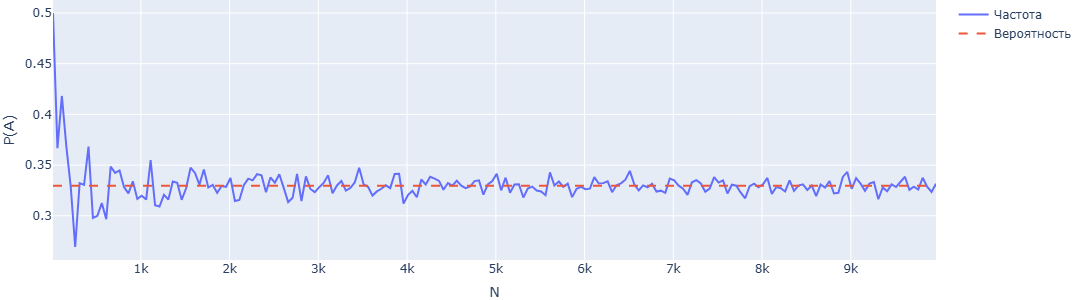

In [2]:
from random import sample
import plotly.graph_objs as go
import numpy as np

def random_shuffle():
    playlist = ['Любимая'] * 5 + ['Обычная'] * 10
    return sample(playlist, 4)

N_values = np.array(range(10, 10001, 50))
P_A_values = []
for N in N_values:
    N_A = 0
    for _ in range(N):
        songs = random_shuffle()
        if songs.count('Любимая') == 2:
            N_A += 1
    P_A_values.append(N_A / N)
print(round(P_A_values[-1], 4))

P = [p] * len(N_values)
fig = go.Figure(layout=dict(width=600, height=300))
fig.update_layout(margin=dict(l=0, t=0, b=0))
fig.add_trace(go.Scatter(x=N_values, y=P_A_values, name='Частота'))
fig.add_trace(go.Scatter(x=N_values, y=P,
                         name='Вероятность', line_dash='dash'))
fig.update_xaxes(title_text='N')
fig.update_yaxes(title_text='P(A)')
fig.show();